# EA3 – Comparación climática: Medellín y Madrid
Nombre: Nombre: Donaldo Andres Otálvaro  Fecha: noviembre 20 del 2026

**Pregunta guía:** ¿Qué similitudes y diferencias se observan en las variables climáticas de Medellín y la otra ciudad durante el mismo periodo?

## 1. Fuentes de datos

| Campo | Medellín | Madrid (España) |
|---|---|---|
| Fuente | Open-Meteo Historical Weather API | Open-Meteo Historical Weather API |
| Enlace | https://open-meteo.com/en/docs/historical-weather-api | https://open-meteo.com/en/docs/historical-weather-api |
| Ciudad | Medellín (6.2442, -75.5812) | Madrid (40.4168, -3.7038) |
| Columnas usadas | `temperature_2m_max`, `temperature_2m_min`, `precipitation_sum` | las mismas |
| Periodo | 2025-01-01 a 2025-12-31 | 2025-01-01 a 2025-12-31 |
| Frecuencia | Diaria | Diaria |
| Unidades | °C y mm | °C y mm |

## 2. Planteamiento de la comparación

**Predicción (antes de calcular):** - Medellín con 1.500 m de altitud, cerca del ecuador tendrá una temperatura casi constante todo el año, con poca variación entre meses.
- Madrid (latitud media, 4 estaciones) tendrá una gran variación estacional: inviernos fríos y veranos calurosos.
- Medellín tendrá muchos más días lluviosos, repartidos casi todo el año. Madrid será más seco, sobre todo en verano.

**Periodo común:** 2025-01-01 a 2025-12-31.

**Variables que vamos a comparar:** temperatura máxima diaria °C, temperatura mínima diaria °C y precipitación diaria mm.

## 3. Carga y revisión de los datos

In [11]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("datos", exist_ok=True)

INICIO, FIN = "2025-01-01", "2025-12-31"
URL = "https://archive-api.open-meteo.com/v1/archive"
VARIABLES = "temperature_2m_max,temperature_2m_min,precipitation_sum"

CIUDADES = {
    "Medellín": {"lat": 6.2442,  "lon": -75.5812, "archivo": "datos/medellin_2025.csv"},
    "Madrid":   {"lat": 40.4168, "lon": -3.7038,  "archivo": "datos/madrid_2025.csv"},
}

def descargar(nombre, cfg):
    if os.path.exists(cfg["archivo"]):
        print(f"{nombre}: ya existe {cfg['archivo']}")
        return
    params = {"latitude": cfg["lat"], "longitude": cfg["lon"],
              "start_date": INICIO, "end_date": FIN,
              "daily": VARIABLES, "timezone": "auto"}
    r = requests.get(URL, params=params, timeout=60)
    r.raise_for_status()
    pd.DataFrame(r.json()["daily"]).to_csv(cfg["archivo"], index=False)
    print(f"{nombre}: descargado en {cfg['archivo']}")

for n, c in CIUDADES.items():
    descargar(n, c)

Medellín: ya existe datos/medellin_2025.csv
Madrid: ya existe datos/madrid_2025.csv


In [12]:
def cargar(archivo):
    df = pd.read_csv(archivo)
    df = df.rename(columns={"time": "fecha", "temperature_2m_max": "tmax",
                            "temperature_2m_min": "tmin", "precipitation_sum": "precip"})
    df["fecha"] = pd.to_datetime(df["fecha"])
    for col in ["tmax", "tmin", "precip"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

med = cargar(CIUDADES["Medellín"]["archivo"])
mad = cargar(CIUDADES["Madrid"]["archivo"])

for nombre, df in [("Medellín", med), ("Madrid", mad)]:
    print("=" * 50)
    print(nombre)
    print("Columnas:", list(df.columns))
    print("Dimensiones:", df.shape)
    print("Fecha inicial:", df["fecha"].min().date(), "| Fecha final:", df["fecha"].max().date())
    print(df.dtypes.to_string())
    display(df.head())

Medellín
Columnas: ['fecha', 'tmax', 'tmin', 'temperature_2m_mean', 'precip']
Dimensiones: (365, 5)
Fecha inicial: 2025-01-01 | Fecha final: 2025-12-31
fecha                  datetime64[us]
tmax                          float64
tmin                          float64
temperature_2m_mean           float64
precip                        float64


,fecha,tmax,tmin,temperature_2m_mean,precip
0,2025-01-01,26.1,15.5,19.3,13.5
1,2025-01-02,26.4,16.0,19.6,10.0
2,2025-01-03,23.5,15.6,19.0,8.8
3,2025-01-04,25.9,15.5,19.5,19.4
4,2025-01-05,25.5,16.4,19.6,20.2


Madrid
Columnas: ['fecha', 'tmax', 'tmin', 'temperature_2m_mean', 'precip']
Dimensiones: (365, 5)
Fecha inicial: 2025-01-01 | Fecha final: 2025-12-31
fecha                  datetime64[us]
tmax                          float64
tmin                          float64
temperature_2m_mean           float64
precip                        float64


,fecha,tmax,tmin,temperature_2m_mean,precip
0,2025-01-01,8.0,-0.9,2.9,0.0
1,2025-01-02,8.6,-1.1,2.9,0.0
2,2025-01-03,8.1,-0.2,3.4,0.0
3,2025-01-04,7.6,1.0,4.2,0.0
4,2025-01-05,11.3,3.5,7.4,3.0


In [21]:
for nombre, df in [("Medellín", med), ("Madrid", mad)]:
    print(nombre)
    print("  Valores faltantes:")
    print(df.isna().sum().to_string())
    print("  Fechas duplicadas:", df["fecha"].duplicated().sum())

assert (med["fecha"].values == mad["fecha"].values).all(), "Las fechas no coinciden"
print("\nAmbas tablas cubren las mismas fechas:", len(med), "días")

Medellín
  Valores faltantes:
fecha                  0
tmax                   0
tmin                   0
temperature_2m_mean    0
precip                 0
  Fechas duplicadas: 0
Madrid
  Valores faltantes:
fecha                  0
tmax                   0
tmin                   0
temperature_2m_mean    0
precip                 0
  Fechas duplicadas: 0

Ambas tablas cubren las mismas fechas: 365 días


Los valores faltantes **no** se reemplazan por cero: un `0` de precipitación significa día sin lluvia, mientras que un faltante es un dato desconocido. Por eso se usan funciones que ignoran `NaN` (`np.nanmean`, etc.).

## 4. Análisis con NumPy

### Índices y cortes

In [29]:
fechas = med["fecha"].to_numpy()
tmax_med, tmax_mad = med["tmax"].to_numpy(float), mad["tmax"].to_numpy(float)
tmin_med, tmin_mad = med["tmin"].to_numpy(float), mad["tmin"].to_numpy(float)
prec_med, prec_mad = med["precip"].to_numpy(float), mad["precip"].to_numpy(float)

# Periodo breve: primera semana de julio
sl = slice(181, 188)
print("Fechas:", fechas[sl].astype("datetime64[D]"))
print("Tmax Medellín (°C):", tmax_med[sl])
print("Tmax Madrid (°C):  ", tmax_mad[sl])
print("Precip Medellín (mm):", prec_med[sl])
print("Precip Madrid (mm):  ", prec_mad[sl])

Fechas: ['2025-07-01' '2025-07-02' '2025-07-03' '2025-07-04' '2025-07-05'
 '2025-07-06' '2025-07-07']
Tmax Medellín (°C): [27.7 27.9 28.2 27.4 26.2 26.5 27.4]
Tmax Madrid (°C):   [37.1 37.5 37.1 36.7 35.  35.1 35.9]
Precip Medellín (mm): [0.1 1.  0.6 2.2 2.  0.3 0. ]
Precip Madrid (mm):   [0.  0.1 0.7 0.  0.  0.  0. ]


### Máscaras booleanas (mismo umbral en las dos ciudades)

In [36]:
UMBRAL_LLUVIA = 1.0   # mm: día lluvioso
UMBRAL_CALOR = 25.0   # °C: día que supera el umbral de temperatura

lluvia_med, lluvia_mad = prec_med >= UMBRAL_LLUVIA, prec_mad >= UMBRAL_LLUVIA
calor_med, calor_mad = tmax_med > UMBRAL_CALOR, tmax_mad > UMBRAL_CALOR

print(f"Días lluviosos (>= {UMBRAL_LLUVIA} mm): Medellín = {lluvia_med.sum()} | Madrid = {lluvia_mad.sum()}")
print(f"Días con Tmax > {UMBRAL_CALOR} °C:      Medellín = {calor_med.sum()} | Madrid = {calor_mad.sum()}")

Días lluviosos (>= 1.0 mm): Medellín = 267 | Madrid = 82
Días con Tmax > 25.0 °C:      Medellín = 332 | Madrid = 134


### Medidas descriptivas por ciudad

In [42]:
tabla = pd.DataFrame({
    "Medellín": [np.nanmean(tmax_med), np.nanmin(tmax_med), np.nanmax(tmax_med),
                 np.nanmean(tmin_med), np.nanmin(tmin_med), np.nanmax(tmin_med), np.nansum(prec_med)],
    "Madrid":   [np.nanmean(tmax_mad), np.nanmin(tmax_mad), np.nanmax(tmax_mad),
                 np.nanmean(tmin_mad), np.nanmin(tmin_mad), np.nanmax(tmin_mad), np.nansum(prec_mad)],
}, index=["Tmax promedio (°C)", "Tmax mínima (°C)", "Tmax máxima (°C)",
          "Tmin promedio (°C)", "Tmin mínima (°C)", "Tmin máxima (°C)",
          "Precipitación total (mm)"]).round(2)
display(tabla)

,Medellín,Madrid
Tmax promedio (°C),26.95,21.44
Tmax mínima (°C),21.70,4.30
Tmax máxima (°C),30.00,40.70
Tmin promedio (°C),16.55,11.02
Tmin mínima (°C),14.60,-3.90
Tmin máxima (°C),18.10,26.30
Precipitación total (mm),2193.90,680.40


### Broadcasting
Se apilan las ciudades en una matriz `(2, 365)` y se resta la media de cada ciudad, que tiene forma `(2, 1)`. NumPy la repite a lo largo de los 365 días.

In [47]:
tmax = np.vstack([tmax_med, tmax_mad])                    # (2, 365)
media = np.nanmean(tmax, axis=1, keepdims=True)           # (2, 1)
anomalia = tmax - media                                   # broadcasting
print("Formas:", tmax.shape, media.shape, anomalia.shape)
print("Anomalía de las primeras 5 fechas:\n", anomalia[:, :5].round(2))

# Agregación mensual (necesaria para las gráficas)
meses = fechas.astype("datetime64[M]").astype(int) % 12
prec = np.vstack([prec_med, prec_mad])
tmax_mes = np.array([[np.nanmean(tmax[c][meses == m]) for m in range(12)] for c in range(2)])
prec_mes = np.array([[np.nansum(prec[c][meses == m]) for m in range(12)] for c in range(2)])

Formas: (2, 365) (2, 1) (2, 365)
Anomalía de las primeras 5 fechas:
 [[ -0.85  -0.55  -3.45  -1.05  -1.45]
 [-13.44 -12.84 -13.34 -13.84 -10.14]]


## 5. Gráficas comparativas

### Gráfica 1: temperatura máxima mensual.

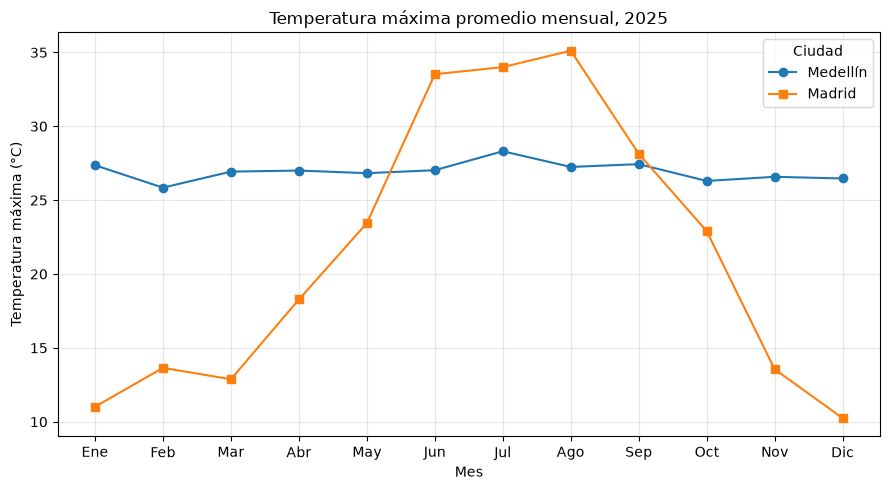

In [51]:
etiquetas = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
x = np.arange(12)

plt.figure(figsize=(9, 5))
plt.plot(x, tmax_mes[0], marker="o", label="Medellín")
plt.plot(x, tmax_mes[1], marker="s", label="Madrid")
plt.xticks(x, etiquetas)
plt.title("Temperatura máxima promedio mensual, 2025")
plt.xlabel("Mes")
plt.ylabel("Temperatura máxima (°C)")
plt.grid(alpha=0.3)
plt.legend(title="Ciudad")
plt.tight_layout()
plt.show()

**Patrón observado:** 
- La temperatura maxima de Medellín es casi constante durante el año. Se mantienee entre unos 26 °C y 28 °C, con un leve maximo en Julio. La de Madrid cambia mucho está cerca de 10 °C o 11 °C en diciembre y enero, sube desde marzo hasta unos 35 °C en agosto y baja rápido desde septiembre. Las dos líneas se cruzan dos veces. De junio a septiembre Madrid es más cálida que Medellín, y el resto del año Medellín es claramente más cálida. 
- También se observa que la temperatura de Madrid describe una forma parecida a una campana. En los primeros meses del año la temperatura aumenta de forma notoria hasta alcanzar su punto más alto en los meses centrales de junio a agosto. Después empieza a descender hasta diciembre, de manera casi igual a como había ascendido.
- Madrid presenta mayores cambios de temperatura según el mes.
- Madrid es más caliente que Medellín durante junio, julio, agosto y septiembre.

**Qué no permite concluir:** 
- No permite decir que el clima de cada ciudad sea siempre así, porque solo se analiza el año 2025. Al ser un promedio mensual, tampoco muestra los días extremos ni la variación dentro de cada mes. No explica la causa de la diferencia como latitud, altitud o estaciones. Tampoco dice nada sobre las temperaturas mínimas ni sobre la sensación térmica.
- No permite saber la temperatura exacta de cada día.
- No permite concluir cómo será la temperatura en los próximos años.

### Gráfica 2: precipitación acumulada por mes.

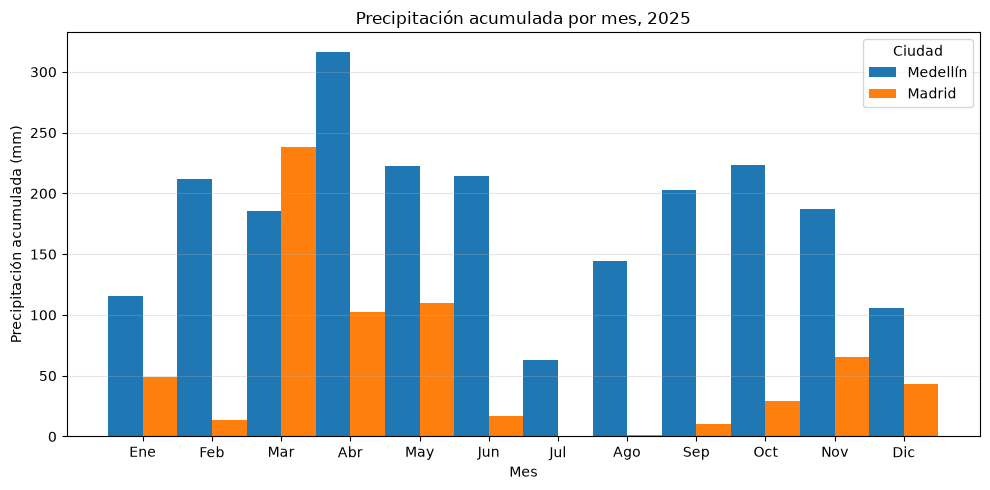

In [ ]:
ancho = 0.5
plt.figure(figsize=(10, 5))
plt.bar(x - ancho/2, prec_mes[0], width=ancho, label="Medellín")
plt.bar(x + ancho/2, prec_mes[1], width=ancho, label="Madrid")
plt.xticks(x, etiquetas)
plt.title("Precipitación acumulada por mes, 2025")
plt.xlabel("Mes")
plt.ylabel("Precipitación acumulada (mm)")
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Ciudad")
plt.tight_layout()
plt.show()

**Patrón observado:** 
- Medellín llovió todos los meses, con totales entre unos 60 mm julio y más de 300 mm abril. Los meses más lluviosos fueron abril, mayo, junio y octubre, y julio fue el más seco. Madrid tuvo totales mucho menores casi todo el año, y entre julio y septiembre casi no llovió. La excepción es marzo, cuando Madrid superó a Medellín cerca de 240 mm frente a unos 185 mm. En los otros 11 meses Medellín acumuló más lluvia.

**Qué no permite concluir:** 
- No permite saber si llovió muchos días con poca lluvia o pocos días con lluvia muy fuerte, porque solo muestra el total mensual. El valor alto de Madrid en marzo podría venir de unos pocos días extremos. Con un solo año tampoco se puede decir que 2025 haya sido normal o atípico, ni definir las temporadas de lluvia de cada ciudad. 


### Gráfica 3: histogramas de la temperatura mínima diaria

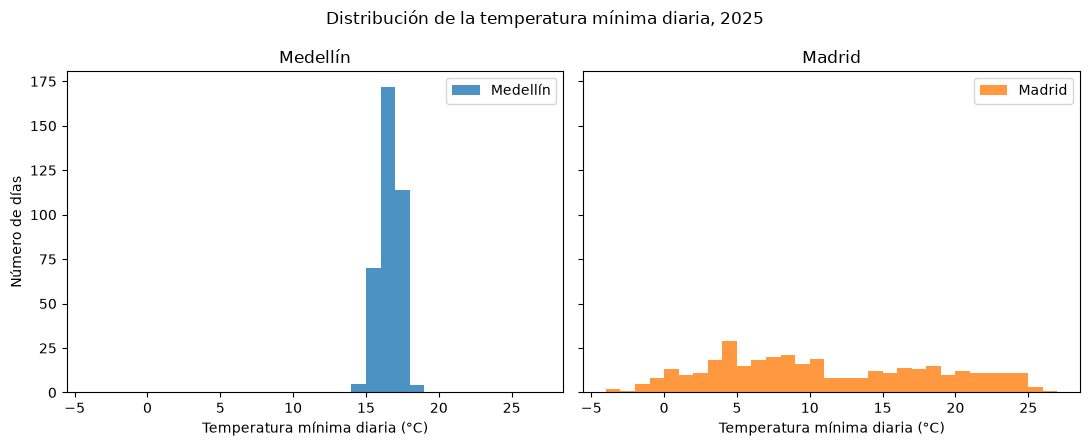

In [53]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
bins = np.arange(np.floor(np.nanmin([tmin_med, tmin_mad])), np.ceil(np.nanmax([tmin_med, tmin_mad])) + 1, 1)

for eje, datos, ciudad, color in zip(ejes, [tmin_med, tmin_mad], ["Medellín", "Madrid"], ["tab:blue", "tab:orange"]):
    eje.hist(datos[~np.isnan(datos)], bins=bins, color=color, alpha=0.8, label=ciudad)
    eje.set_title(ciudad)
    eje.set_xlabel("Temperatura mínima diaria (°C)")
    eje.legend()
ejes[0].set_ylabel("Número de días")
fig.suptitle("Distribución de la temperatura mínima diaria, 2025")
plt.tight_layout()
plt.show()

**Patrón observado:** 
- En Medellín las temperaturas mínimas se concentran en un rango muy estrecho, entre unos 15 °C y 19 °C. La mayoría de los días están en 16 °C o 17 °C, con más de 150 días en la barra más alta. En Madrid la distribución es mucho más ancha: va desde unos -4 °C hasta cerca de 27 °C, sin una concentración clara. Se ve más frecuencia entre 3 °C y 10 °C. Medellín tiene noches muy parecidas entre si, mientras que en Madrid cambian mucho según la época del año.

**Qué no permite concluir:** 
- El histograma no muestra en qué fecha ocurrió cada valor, así que no revela estacionalidad ni rachas de frío o calor. Como los dos paneles comparten el mismo eje vertical, las barras de Madrid se ven bajas porque sus días se reparten en más rangos, no porque haya menos días. Tampoco permite afirmar nada sobre las temperaturas máximas ni sobre el confort. Y las mínimas de Madrid cercanas a 25 °C son altas para una ciudad de interior, así que conviene recordar que son datos de reanálisis y no de una estación.
- No permite afirmar que todos los días de Madrid sean fríos o que todos los de Medellín sean cálidos.


-  Conclusion general:
Al comparar los datos climáticos de Medellín y Madrid durante 2025, se encontró que Medellín presenta temperaturas más estables durante todo el año y mayores precipitaciones en la mayoría de los meses. Por otro lado, Madrid tiene cambios de temperatura mucho más marcados, con veranos calurosos e inviernos fríos, además de menores precipitaciones durante gran parte del año. En conclusión, ambas ciudades presentan comportamientos climáticos diferentes, principalmente por sus características geográficas y estaciones del año. Esta comparación permitió utilizar herramientas como Python, NumPy y Pandas para analizar datos reales y representar los resultados mediante gráficas.